In [1]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import numpy for numerical and mathematical operations
import numpy as np

# Import scipy statistics for statistical calculations and tests
from scipy import stats

# Import matplotlib for creating charts and visualisations
import matplotlib.pyplot as plt

# Display a confirmation message
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Check whether the malaria dataset exists in the current colab session

import os
print(os.path.exists('/content/malaria_programme_data.csv'))

True


In [3]:
# Load the malaria prevention dataset into a pandas DataFrame
df = pd.read_csv('malaria_programme_data.csv')

# Display the first five rows of the dataset
print(df.head())

   household_id lga programme uses_net  haemoglobin  clinic_visits  \
0             1   A       Yes      Yes         10.6              3   
1             2   A        No       No         10.2              1   
2             3   A       Yes      Yes          8.9              2   
3             4   A       Yes      Yes         10.7              1   
4             5   A       Yes       No         11.8              1   

   days_malaria_free  distance_km  
0                 61          2.8  
1                189          6.3  
2                 83          6.2  
3                 81          2.7  
4                 50          2.4  


In [4]:
# Display the number of rows and columns in the dataset
print("Dataset Shape:", df.shape)

# Display the total number of households
print("Total Households:", df.shape[0])

# Display the total number of variables
print("Total Variables:", df.shape[1])

Dataset Shape: (600, 8)
Total Households: 600
Total Variables: 8


In [5]:
# Display the data types of all columns in the dataset
print(df.dtypes)

household_id           int64
lga                   object
programme             object
uses_net              object
haemoglobin          float64
clinic_visits          int64
days_malaria_free      int64
distance_km          float64
dtype: object


In [6]:
# Count the missing values in each column
print("Missing Values Per Column:")
print(df.isnull().sum())

# Calculate the total number of missing values in the entire dataset
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values Per Column:
household_id         0
lga                  0
programme            0
uses_net             0
haemoglobin          0
clinic_visits        0
days_malaria_free    0
distance_km          0
dtype: int64

Total Missing Values:
0


In [7]:
# Check the dataset for completely duplicated rows
duplicate_count = df.duplicated().sum()

# Display the total number of duplicate records
print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [8]:
# Count the number of unique household identification numbers
unique_ids = df['household_id'].nunique()

# Display the number of unique household IDs
print("Unique Household IDs:", unique_ids)

# Check whether any household ID appears more than once
print("Duplicate Household IDs:", df['household_id'].duplicated().sum())

Unique Household IDs: 600
Duplicate Household IDs: 0


In [9]:
# Count the number of households in each Local Government Area
print("Households by LGA:")
print(df['lga'].value_counts())

# Count households according to programme participation
print("\nProgramme Participation:")
print(df['programme'].value_counts())

# Count households according to mosquito net usage
print("\nMosquito Net Usage:")
print(df['uses_net'].value_counts())

Households by LGA:
lga
A    200
B    200
C    200
Name: count, dtype: int64

Programme Participation:
programme
No     305
Yes    295
Name: count, dtype: int64

Mosquito Net Usage:
uses_net
Yes    333
No     267
Name: count, dtype: int64


In [10]:
# Select the four numerical variables for examination
numerical_data = df[['haemoglobin', 'clinic_visits', 'days_malaria_free', 'distance_km']]

# Display basic descriptive information about the numerical variables
print(numerical_data.describe())

       haemoglobin  clinic_visits  days_malaria_free  distance_km
count   600.000000     600.000000         600.000000   600.000000
mean     11.050167       1.446667         105.853333     4.326833
std       1.525695       1.217769         105.816604     4.398296
min       6.400000       0.000000           1.000000     0.400000
25%      10.000000       1.000000          29.000000     2.200000
50%      11.100000       1.000000          72.500000     3.400000
75%      12.000000       2.000000         151.000000     5.100000
max      16.000000       6.000000         805.000000    55.000000


In [11]:
# Select the four numerical variables for statistical analysis
columns = ['haemoglobin', 'clinic_visits', 'days_malaria_free', 'distance_km']

# Calculate the mean of each numerical variable
mean = df[columns].mean()

# Calculate the median of each numerical variable
median = df[columns].median()

# Calculate the sample variance using n minus 1
variance = df[columns].var(ddof=1)

# Calculate the sample standard deviation using n minus 1
std_dev = df[columns].std(ddof=1)

# Combine all the calculated statistics into one summary table
summary = pd.DataFrame({
    'Mean': mean,
    'Median': median,
    'Variance': variance,
    'Standard Deviation': std_dev
})

# Display the descriptive statistics summary
print("DESCRIPTIVE STATISTICS")
print(summary)

# Calculate the mode of clinic visits
clinic_mode = df['clinic_visits'].mode()

# Display the mode of clinic visits
print("\nMODE OF CLINIC VISITS:")
print(clinic_mode.tolist())

DESCRIPTIVE STATISTICS
                         Mean  Median      Variance  Standard Deviation
haemoglobin         11.050167    11.1      2.327746            1.525695
clinic_visits        1.446667     1.0      1.482960            1.217769
days_malaria_free  105.853333    72.5  11197.153745          105.816604
distance_km          4.326833     3.4     19.345005            4.398296

MODE OF CLINIC VISITS:
[1]


In [12]:
# Select the distance variable from the dataset
distance = df['distance_km']

# Calculate the first quartile (25th percentile)
Q1 = distance.quantile(0.25)

# Calculate the third quartile (75th percentile)
Q3 = distance.quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Display the calculated quartiles and interquartile range
print("First Quartile (Q1):", Q1)
print("Third Quartile (Q3):", Q3)
print("Interquartile Range (IQR):", IQR)

First Quartile (Q1): 2.2
Third Quartile (Q3): 5.1
Interquartile Range (IQR): 2.8999999999999995


In [13]:
# Calculate the lower boundary for identifying potential outliers
lower_fence = Q1 - (1.5 * IQR)

# Calculate the upper boundary for identifying potential outliers
upper_fence = Q3 + (1.5 * IQR)

# Display the calculated lower and upper boundaries
print("Lower Fence:", lower_fence)
print("Upper Fence:", upper_fence)

Lower Fence: -2.1499999999999995
Upper Fence: 9.45


In [14]:
# Identify households with distances below the lower fence or above the upper fence
outliers = df[(distance < lower_fence) | (distance > upper_fence)]

# Display the total number of potential outliers
print("Number of Potential Outliers:", len(outliers))

# Display the distances identified as potential outliers
print("\nPotential Outlier Distances:")
print(outliers['distance_km'].sort_values(ascending=False).to_list())

Number of Potential Outliers: 28

Potential Outlier Distances:
[55.0, 47.0, 42.5, 38.0, 29.2, 19.0, 16.0, 15.3, 14.5, 14.1, 13.8, 13.7, 13.0, 11.5, 11.5, 11.4, 11.1, 11.1, 10.9, 10.8, 10.5, 9.9, 9.8, 9.7, 9.7, 9.6, 9.6, 9.5]


In [15]:
# Sort the dataset by distance from highest to lowest
sorted_distances = df.sort_values('distance_km', ascending=False)

# Display the six households with the greatest distances from their nearest clinics
print(sorted_distances.head(6))

     household_id lga programme uses_net  haemoglobin  clinic_visits  \
34             35   A       Yes       No         11.6              0   
190           191   A       Yes      Yes         11.9              3   
216           217   B       Yes      Yes         13.4              0   
192           193   A       Yes      Yes         11.5              3   
116           117   A       Yes      Yes         10.3              2   
285           286   B        No      Yes          9.6              1   

     days_malaria_free  distance_km  
34                 278         55.0  
190                 63         47.0  
216                 90         42.5  
192                101         38.0  
116                 85         29.2  
285                 27         19.0  


In [16]:
# Calculate the mean distance using all 600 households
mean_before = df['distance_km'].mean()

# Calculate the median distance using all 600 households
median_before = df['distance_km'].median()

# Calculate the skewness of distances using all 600 households
skew_before = df['distance_km'].skew()

# Create a comparison dataset excluding distances above 30 km
distance_clean = df[df['distance_km'] <= 30]['distance_km']

# Calculate the mean distance after excluding distances above 30 km
mean_after = distance_clean.mean()

# Calculate the median distance after excluding distances above 30 km
median_after = distance_clean.median()

# Calculate the skewness after excluding distances above 30 km
skew_after = distance_clean.skew()

# Display the statistics before and after the exclusion
comparison = pd.DataFrame({
    'Before Exclusion': [mean_before, median_before, skew_before],
    'After Exclusion': [mean_after, median_after, skew_after]
}, index=['Mean', 'Median', 'Skewness'])

print(comparison)

          Before Exclusion  After Exclusion
Mean              4.326833         4.049664
Median            3.400000         3.400000
Skewness          6.501394         2.575054


In [17]:
# Select the days malaria-free column
days_free = df['days_malaria_free']

# Calculate the skewness of the days malaria-free variable
days_skewness = days_free.skew()

# Display the skewness result
print("Skewness of Days Malaria-Free:", days_skewness)

Skewness of Days Malaria-Free: 2.0114504883929865


The skewness of days_malaria_free is 2.0115, indicating a positively skewed or right-skewed distribution. This suggests that many households experienced relatively shorter malaria-free periods, while a smaller number experienced much longer periods before the next malaria episode.

In [18]:
# Calculate the proportion of households that use bed nets
p_net = (df['uses_net'] == 'Yes').mean()

# Calculate the probability that at least 15 out of 20 households use bed nets
probability = stats.binom.sf(14, n=20, p=p_net)

# Display the estimated bed-net usage proportion
print("Bed-net usage proportion:", p_net)

# Display the probability of at least 15 households using bed nets
print("Probability of at least 15 out of 20:", probability)

# Convert the probability into a percentage
print("Probability as a percentage:", probability * 100, "%")

Bed-net usage proportion: 0.555
Probability of at least 15 out of 20: 0.060488620839608015
Probability as a percentage: 6.048862083960802 %


In [19]:
# Select the clinic visits column from the dataset
clinic_visits = df['clinic_visits']

# Calculate the average number of clinic visits per household
visit_mean = clinic_visits.mean()

# Calculate the sample variance of clinic visits
visit_variance = clinic_visits.var(ddof=1)

# Display the average number of clinic visits
print("Mean clinic visits:", visit_mean)

# Display the variance of clinic visits
print("Variance of clinic visits:", visit_variance)

Mean clinic visits: 1.4466666666666668
Variance of clinic visits: 1.4829604897050586


In [20]:
# Use the average clinic visits as the Poisson rate (lambda)
lam = visit_mean

# Calculate the probability of more than 3 clinic visits
prob_more_than_3 = stats.poisson.sf(3, mu=lam)

# Calculate the probability of exactly zero clinic visits
prob_zero_visits = stats.poisson.pmf(0, mu=lam)

# Display the Poisson rate
print("Poisson rate (lambda):", lam)

# Display the probability of more than 3 clinic visits
print("Probability of more than 3 visits:", prob_more_than_3)

# Convert the probability into a percentage
print("Percentage of more than 3 visits:", prob_more_than_3 * 100, "%")

# Display the probability of no clinic visits
print("Probability of zero visits:", prob_zero_visits)

# Convert the probability into a percentage
print("Percentage of zero visits:", prob_zero_visits * 100, "%")

Poisson rate (lambda): 1.4466666666666668
Probability of more than 3 visits: 0.05912805893772032
Percentage of more than 3 visits: 5.912805893772032 %
Probability of zero visits: 0.23535349367154965
Percentage of zero visits: 23.535349367154964 %


In [21]:
# Select the days malaria-free column
days_free = df['days_malaria_free']

# Calculate the average waiting time until the next malaria episode
mean_waiting_time = days_free.mean()

# Calculate the exponential rate parameter
exp_rate = 1 / mean_waiting_time

# Display the average waiting time
print("Mean waiting time:", mean_waiting_time, "days")

# Display the exponential rate parameter
print("Exponential rate:", exp_rate)

Mean waiting time: 105.85333333333334 days
Exponential rate: 0.009447033631439727


In [22]:
# Calculate the probability of remaining malaria-free for more than 90 days
prob_more_than_90 = stats.expon.sf(90, scale=mean_waiting_time)

# Calculate the probability of experiencing a malaria episode within 30 days
prob_within_30 = stats.expon.cdf(30, scale=mean_waiting_time)

# Display the probability of staying malaria-free for more than 90 days
print("Probability of more than 90 malaria-free days:", prob_more_than_90)

# Convert the probability into a percentage
print("Percentage of more than 90 malaria-free days:", prob_more_than_90 * 100, "%")

# Display the probability of an episode within 30 days
print("Probability of an episode within 30 days:", prob_within_30)

# Convert the probability into a percentage
print("Percentage of an episode within 30 days:", prob_within_30 * 100, "%")

Probability of more than 90 malaria-free days: 0.42731534440595675
Percentage of more than 90 malaria-free days: 42.731534440595674 %
Probability of an episode within 30 days: 0.24678985187525604
Percentage of an episode within 30 days: 24.678985187525605 %


In [23]:
# Select the haemoglobin column from the dataset
haemoglobin = df['haemoglobin']

# Calculate the skewness of haemoglobin levels
hb_skewness = haemoglobin.skew()

# Display the skewness result
print("Haemoglobin skewness:", hb_skewness)

Haemoglobin skewness: 0.028710318690201585


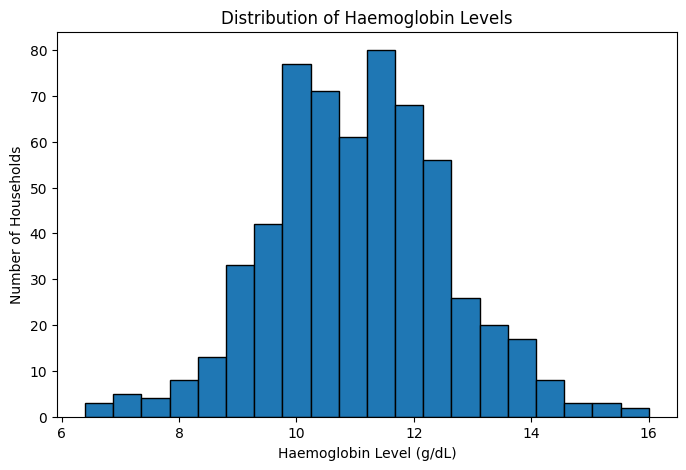

In [24]:
# Create a figure for the haemoglobin histogram
plt.figure(figsize=(8, 5))

# Draw a histogram using the haemoglobin values
plt.hist(haemoglobin, bins=20, edgecolor='black')

# Add a title to the histogram
plt.title('Distribution of Haemoglobin Levels')

# Label the horizontal axis
plt.xlabel('Haemoglobin Level (g/dL)')

# Label the vertical axis
plt.ylabel('Number of Households')

# Display the histogram
plt.show()

In [25]:
# Select the haemoglobin column from the dataset
hb = df['haemoglobin']

# Set the national haemoglobin benchmark
mu0 = 11.5

# Set the known population standard deviation
sigma = 1.5

# Calculate the number of households in the sample
n = len(hb)

# Calculate the sample mean haemoglobin
xbar = hb.mean()

# Display the national benchmark
print("National benchmark:", mu0)

# Display the known population standard deviation
print("Population standard deviation:", sigma)

# Display the sample size
print("Sample size:", n)

# Display the sample mean
print("Sample mean haemoglobin:", xbar)

National benchmark: 11.5
Population standard deviation: 1.5
Sample size: 600
Sample mean haemoglobin: 11.050166666666666


In [26]:
# Calculate the standard error using the known population standard deviation
se = sigma / np.sqrt(n)

# Display the calculated standard error
print("Standard Error:", se)

Standard Error: 0.06123724356957946


In [27]:
# Calculate the z-statistic by comparing the sample mean with the national benchmark
z_statistic = (xbar - mu0) / se

# Display the calculated z-statistic
print("Z-statistic:", z_statistic)

Z-statistic: -7.345747573079789


In [28]:
# Calculate the left-tailed p-value using the standard normal distribution
p_value = stats.norm.cdf(z_statistic)

# Display the calculated p-value
print("Left-tailed p-value:", p_value)

Left-tailed p-value: 1.0230610691454319e-13


In [29]:
# Calculate the critical z-value for a 95% confidence interval
z_critical = stats.norm.ppf(0.975)

# Calculate the margin of error
margin_error = z_critical * se

# Calculate the lower confidence limit
ci_lower = xbar - margin_error

# Calculate the upper confidence limit
ci_upper = xbar + margin_error

# Display the critical z-value
print("Critical z-value:", z_critical)

# Display the margin of error
print("Margin of error:", margin_error)

# Display the 95% confidence interval
print("95% Confidence Interval:", ci_lower, "to", ci_upper)

Critical z-value: 1.959963984540054
Margin of error: 0.12002279190888275
95% Confidence Interval: 10.930143874757784 to 11.170189458575548


In [30]:
# Select haemoglobin values for households that participated in the programme
programme_yes = df.loc[df['programme'] == 'Yes', 'haemoglobin']

# Select haemoglobin values for households that did not participate
programme_no = df.loc[df['programme'] == 'No', 'haemoglobin']

# Calculate the mean haemoglobin for programme households
mean_yes = programme_yes.mean()

# Calculate the mean haemoglobin for non-programme households
mean_no = programme_no.mean()

# Display the number of households in each group
print("Programme households:", len(programme_yes))
print("Non-programme households:", len(programme_no))

# Display the mean haemoglobin for programme households
print("Mean haemoglobin (Programme):", mean_yes)

# Display the mean haemoglobin for non-programme households
print("Mean haemoglobin (Non-programme):", mean_no)

Programme households: 295
Non-programme households: 305
Mean haemoglobin (Programme): 11.17593220338983
Mean haemoglobin (Non-programme): 10.928524590163933


In [31]:
# Perform Welch's two-sample t-test without assuming equal group variances
t_result = stats.ttest_ind(programme_yes, programme_no, equal_var=False)

# Display the calculated t-statistic
print("T-statistic:", t_result.statistic)

# Display the p-value from the two-tailed test
print("P-value:", t_result.pvalue)

# Display the degrees of freedom
print("Degrees of freedom:", t_result.df)

T-statistic: 1.9916656309943985
P-value: 0.046862154563412264
Degrees of freedom: 597.9913472083554


In [32]:
# Calculate the difference between the two group means
mean_difference = mean_yes - mean_no

# Calculate the 95% confidence interval for the difference using Welch's test
ci_difference = t_result.confidence_interval(confidence_level=0.95)

# Display the difference between the group means
print("Difference in means:", mean_difference)

# Display the lower confidence limit
print("Lower 95% confidence limit:", ci_difference.low)

# Display the upper confidence limit
print("Upper 95% confidence limit:", ci_difference.high)

# Display the complete 95% confidence interval
print("95% Confidence Interval:", ci_difference.low, "to", ci_difference.high)

Difference in means: 0.24740761322589755
Lower 95% confidence limit: 0.0034442480976546452
Upper 95% confidence limit: 0.49137097835414045
95% Confidence Interval: 0.0034442480976546452 to 0.49137097835414045


In [33]:
# Calculate the average of the two groups' sample variances
average_variance = (programme_yes.var(ddof=1) + programme_no.var(ddof=1)) / 2

# Calculate the standard deviation used to standardise the difference
pooled_sd = np.sqrt(average_variance)

# Calculate Cohen's d using the difference between the group means
cohens_d = mean_difference / pooled_sd

# Display the standard deviation used in the calculation
print("Standard deviation:", pooled_sd)

# Display Cohen's d
print("Cohen's d:", cohens_d)

Standard deviation: 1.5215597473644267
Cohen's d: 0.16260131332630562


In [34]:
# Create a contingency table showing bed-net usage across the three LGAs
lga_net_table = pd.crosstab(df['lga'], df['uses_net'])

# Display the contingency table
print("Bed-net usage by LGA:")
print(lga_net_table)

Bed-net usage by LGA:
uses_net   No  Yes
lga               
A          90  110
B          71  129
C         106   94


In [35]:
# Select haemoglobin values for households that participated in the programme
programme_yes = df.loc[df['programme'] == 'Yes', 'haemoglobin']

# Select haemoglobin values for households that did not participate
programme_no = df.loc[df['programme'] == 'No', 'haemoglobin']

# Calculate the mean haemoglobin for programme households
mean_yes = programme_yes.mean()

# Calculate the mean haemoglobin for non-programme households
mean_no = programme_no.mean()

# Display the number of households in each group
print("Programme households:", len(programme_yes))
print("Non-programme households:", len(programme_no))

# Display the mean haemoglobin for programme households
print("Mean haemoglobin (Programme):", mean_yes)

# Display the mean haemoglobin for non-programme households
print("Mean haemoglobin (Non-programme):", mean_no)

Programme households: 295
Non-programme households: 305
Mean haemoglobin (Programme): 11.17593220338983
Mean haemoglobin (Non-programme): 10.928524590163933


In [36]:
# Perform the chi-square test of independence
chi2_lga, p_lga, dof_lga, expected_lga = stats.chi2_contingency(lga_net_table)

# Display the chi-square test statistic
print("Chi-square statistic:", chi2_lga)

# Display the p-value
print("P-value:", p_lga)

# Display the degrees of freedom
print("Degrees of freedom:", dof_lga)

# Display the expected frequencies
print("Expected frequencies:")
print(expected_lga)

Chi-square statistic: 12.430407936025913
P-value: 0.001998808615808526
Degrees of freedom: 2
Expected frequencies:
[[ 89. 111.]
 [ 89. 111.]
 [ 89. 111.]]


In [37]:
# Create a contingency table comparing programme participation with bed-net usage
programme_net_table = pd.crosstab(df['programme'], df['uses_net'])

# Display the contingency table
print("Bed-net usage by programme participation:")
print(programme_net_table)

Bed-net usage by programme participation:
uses_net    No  Yes
programme          
No         178  127
Yes         89  206


In [38]:
# Perform the chi-square test of independence
chi2_programme, p_programme, dof_programme, expected_programme = stats.chi2_contingency(programme_net_table)

# Display the chi-square test statistic
print("Chi-square statistic:", chi2_programme)

# Display the p-value
print("P-value:", p_programme)

# Display the degrees of freedom
print("Degrees of freedom:", dof_programme)

# Display the expected frequencies under the null hypothesis
print("Expected frequencies:")
print(expected_programme)

Chi-square statistic: 47.120437932492486
P-value: 6.675594654740575e-12
Degrees of freedom: 1
Expected frequencies:
[[135.725 169.275]
 [131.275 163.725]]


In [39]:
# Count the total number of households surveyed
n_households = len(df)

# Count the number of households that use bed nets
net_users_count = (df['uses_net'] == 'Yes').sum()

# Calculate the sample proportion of households using bed nets
sample_proportion = net_users_count / n_households

# Set the significance level for a 95% confidence interval
alpha = 0.05

# Display the total number of households
print("Total households:", n_households)

# Display the number of households using bed nets
print("Households using bed nets:", net_users_count)

# Display the sample proportion
print("Sample proportion:", sample_proportion)

# Display the sample proportion as a percentage
print("Bed-net usage percentage:", sample_proportion * 100, "%")

Total households: 600
Households using bed nets: 333
Sample proportion: 0.555
Bed-net usage percentage: 55.50000000000001 %


In [40]:
# Calculate the standard error of the sample proportion
proportion_se = np.sqrt((sample_proportion * (1 - sample_proportion)) / n_households)

# Display the standard error
print("Standard error of proportion:", proportion_se)

Standard error of proportion: 0.02028854356527348


In [41]:
# Calculate the critical z-value for a 95% confidence interval
z_critical_prop = stats.norm.ppf(0.975)

# Calculate the margin of error
margin_error_prop = z_critical_prop * proportion_se

# Calculate the lower confidence limit
prop_ci_lower = sample_proportion - margin_error_prop

# Calculate the upper confidence limit
prop_ci_upper = sample_proportion + margin_error_prop

# Display the critical z-value
print("Critical z-value:", z_critical_prop)

# Display the margin of error
print("Margin of error:", margin_error_prop)

# Display the lower confidence limit as a percentage
print("Lower confidence limit:", prop_ci_lower * 100, "%")

# Display the upper confidence limit as a percentage
print("Upper confidence limit:", prop_ci_upper * 100, "%")

# Display the complete 95% confidence interval
print("95% Confidence Interval:", prop_ci_lower * 100, "% to", prop_ci_upper * 100, "%")

Critical z-value: 1.959963984540054
Margin of error: 0.03976481468670788
Lower confidence limit: 51.523518531329216 %
Upper confidence limit: 59.4764814686708 %
95% Confidence Interval: 51.523518531329216 % to 59.4764814686708 %


In [42]:
# Set the significance level used in our statistical tests
alpha = 0.05

# Calculate the probability of making a Type I error
type_1_error = alpha

# Display the Type I error probability
print("Type I error probability:", type_1_error)

# Display the Type I error probability as a percentage
print("Type I error probability percentage:", type_1_error * 100, "%")

Type I error probability: 0.05
Type I error probability percentage: 5.0 %


In [43]:
# Perform the chi-square test without Yates' continuity correction
chi2_uncorrected, p_uncorrected, dof_uncorrected, expected_uncorrected = stats.chi2_contingency(
    programme_net_table,
    correction=False
)

# Display the uncorrected chi-square statistic
print("Chi-square statistic without correction:", chi2_uncorrected)

# Display the uncorrected p-value
print("P-value without correction:", p_uncorrected)

# Display the degrees of freedom
print("Degrees of freedom:", dof_uncorrected)

Chi-square statistic without correction: 48.255145948949796
P-value without correction: 3.7421487144778985e-12
Degrees of freedom: 1


The chi-square test was performed with and without Yates' continuity correction. With the correction, the chi-square statistic was 47.1204 and the p-value was 6.6756 × 10⁻¹². Without the correction, the chi-square statistic was 48.2551 and the p-value was 3.7421 × 10⁻¹². Although the correction slightly reduced the chi-square statistic and increased the p-value, both p-values were below the 0.05 significance level. Therefore, the statistical decision did not change, and the null hypothesis was rejected in both cases. There is strong evidence of an association between programme participation and bed-net usage.

### 1. Recommendation

**The State Ministry of Health should fix the existing malaria prevention programme before expanding it statewide.**

The programme shows promising results, as households that participated had higher bed-net usage than those that did not participate. However, overall bed-net usage remains substantially below the state's 80% target, with none of the three LGAs achieving the required coverage. The Ministry should strengthen programme implementation, prioritise LGA C, where bed-net usage is lowest, and investigate barriers to consistent bed-net use before committing additional resources to statewide expansion.

### 2. Evidence

1. **Bed-net coverage is below the state target.** Only 55.5% of the 600 households surveyed reported using bed nets. The 95% confidence interval was 51.52%–59.48%, entirely below the 80% target. This indicates that current coverage needs substantial improvement before expansion.

2. **Coverage varies across the three LGAs.** Bed-net usage was 55% in LGA A, 64.5% in LGA B and 47% in LGA C. The chi-square test found a statistically significant association between LGA and bed-net usage (χ² = 12.43, p = 0.002). LGA C therefore deserves priority attention.

3. **Programme participation is associated with higher bed-net usage.** Usage was 69.83% among programme households, compared with 41.64% among non-programme households. The association was statistically significant (χ² = 47.12, p less than 0.001). This supports improving and retaining the programme, although it does not establish that participation caused the higher usage.

4. **The haemoglobin improvement was modest.** Programme households had a mean haemoglobin level 0.2474 g/dL higher than non-programme households (95% confidence interval: 0.0034–0.4914 g/dL). Although statistically significant, the effect size was very small (Cohen's d = 0.1626), so the health benefit should not be overstated.

### 3. Risk of Being Wrong

A Type I error would occur if the analysis concluded that the state's mean haemoglobin level was below the national benchmark of 11.5 g/dL when it was not. This could lead the government to redirect scarce public health resources unnecessarily.

A Type II error would occur if the analysis failed to identify that the state's mean haemoglobin level was genuinely below the benchmark. This could cause the government to overlook a real health concern and delay necessary intervention.

A Type II error worries me more because overlooking a genuine public health problem could have serious consequences for households. However, the possibility of a Type I error also supports a cautious approach. The government should strengthen the existing programme, investigate implementation gaps and monitor improvements before committing to statewide expansion.

### 4. Limitations

This analysis has some limitations. First, although the 600 households were sampled from three LGAs, the dataset does not explain how they were selected. This makes it difficult to determine how fully they represent all households in the state.

Second, the higher bed-net usage among programme households does not prove that programme participation caused the difference, as other household or community factors may have influenced the results.

Third, although the difference in haemoglobin levels between programme and non-programme households was statistically significant, the effect size was small, meaning the practical health benefit may be limited.

Finally, the available data do not provide a complete assessment of malaria incidence, severity and mortality. Further monitoring and more direct health-outcome data are needed before making stronger claims about the programme's overall effectiveness.